# Example of the aitlas toolbox in the context of object detection in remote sensing images

## Import the required packages

In [ ]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning) 
warnings.filterwarnings("ignore", category=DeprecationWarning) 

from aitlas.datasets import SIMDDataset 
from aitlas.transforms import Resize
from aitlas.utils import image_loader
from aitlas.models import FasterRCNN

## Visualize images and objects witn bounding boxes

Total number of patches: 5000


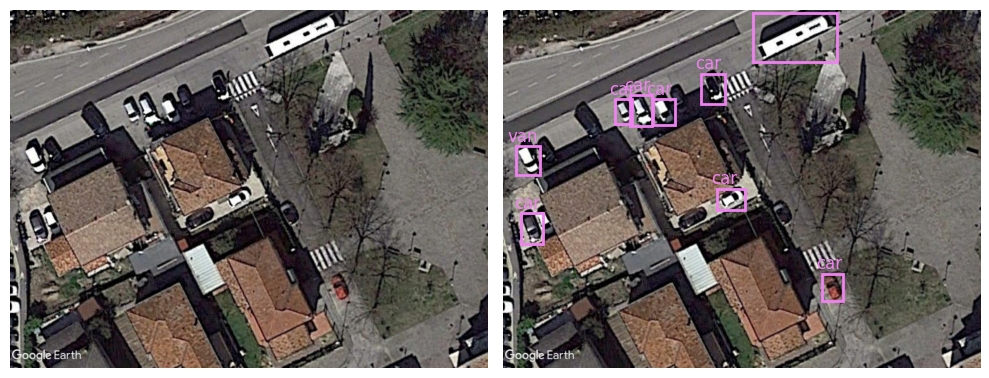

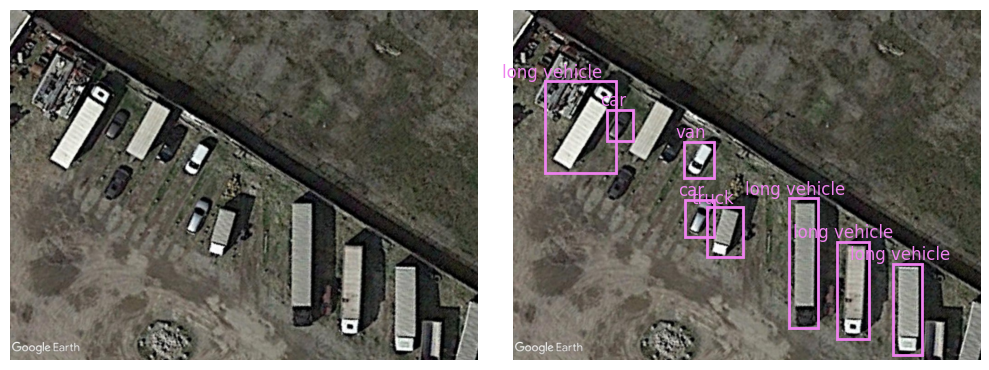

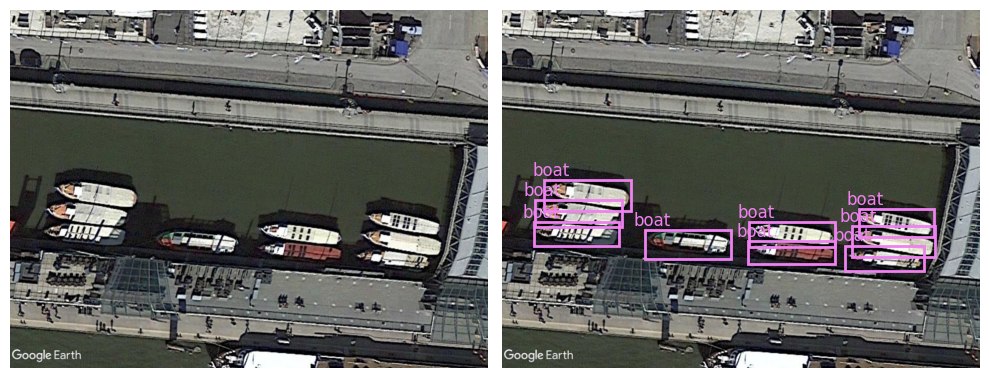

In [11]:
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/SIMD/images/",
    "annotation_dir": "/home/dragik/data/FAIR_EO/SIMD/annotations/",
}
dataset = SIMDDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(1);
dataset.show_image(10);
dataset.show_image(100);

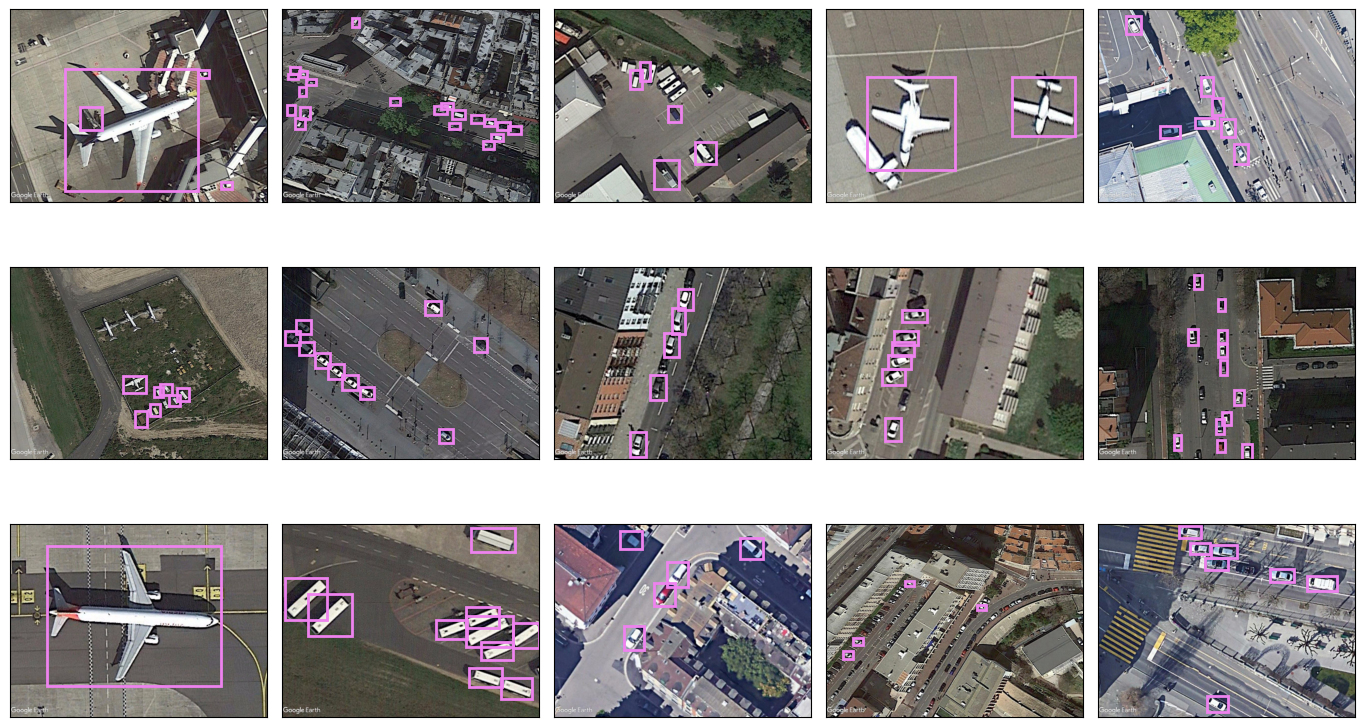

In [12]:
dataset.show_batch(15);

In [13]:
dataset.data_distribution_table()

,Label,Count
0,car,20510
1,truck,2802
2,van,5732
3,long vehicle,1622
4,bus,1991
5,airliner,968
6,propeller aircraft,195
7,trainer aircraft,631
8,chartered aircraft,640
9,fighter aircraft,49


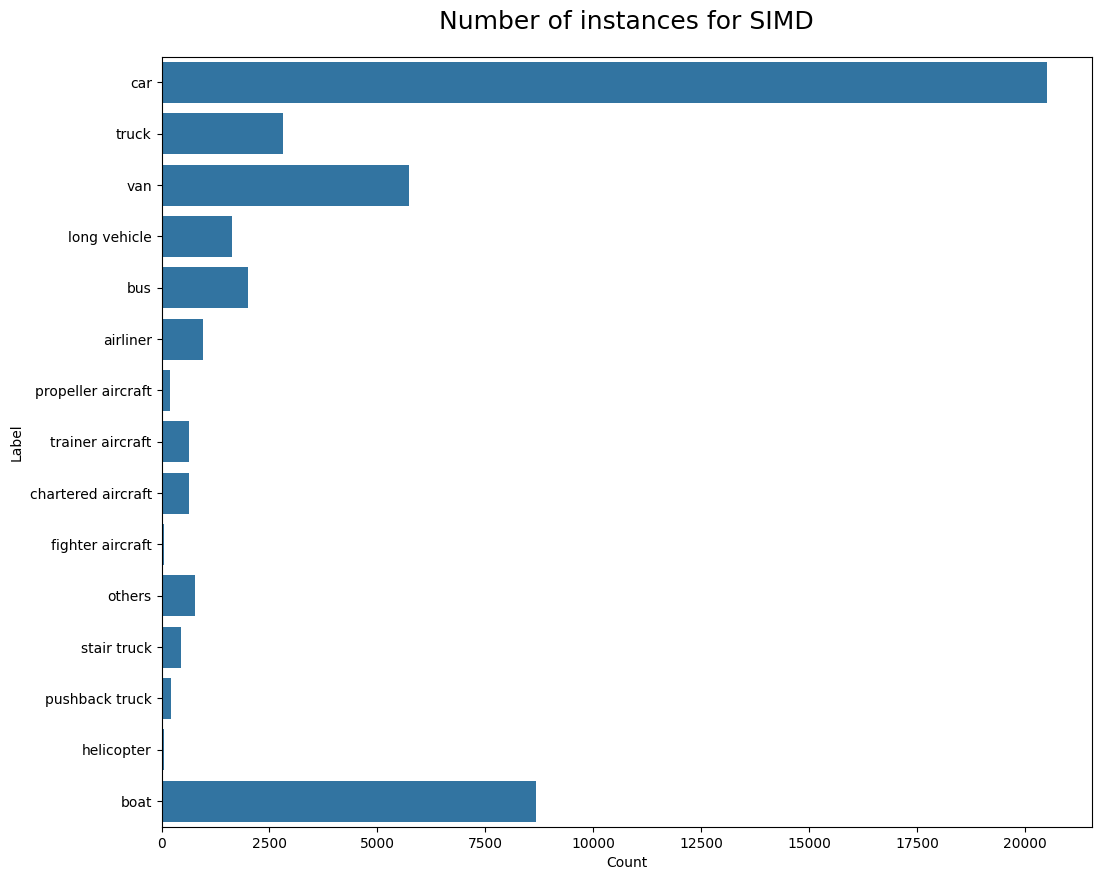

In [14]:
dataset.data_distribution_barchart();

## Load train data

In [20]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "data_dir": "/home/dragik/data/FAIR_EO/SIMD/training/images/",
    "annotation_dir": "/home/dragik/data/FAIR_EO/SIMD/training/annotations/",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}
train_dataset = SIMDDataset(train_dataset_config)

print(f"Total number of train images: {len(train_dataset)}")

Total number of train images: 4000


## Create the model

In [21]:
epochs = 10
model_directory = "/home/dragik/data/FAIR_EO/SIMD/experiments/"
model_config = {
    "num_classes": 15,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}

model = FasterRCNN(model_config)
model.prepare()

## Start the training

In [22]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-05-05 10:17:16,413 INFO Starting training.
training: 100%|██████████| 500/500 [02:46<00:00,  3.01it/s]
2025-05-05 10:20:02,734 INFO epoch: 1, time: 166, loss:  0.38598
testing on train set: 100%|██████████| 500/500 [01:26<00:00,  5.79it/s]
2025-05-05 10:21:49,365 INFO map:0.28827419877052307, map_50:0.40894925594329834, map_75:0.3581196963787079, map_small:0.236585333943367, map_medium:0.2831273078918457, map_large:0.3422812521457672, mar_1:0.1565941572189331, mar_10:0.3309086561203003, mar_100:0.3757784366607666, mar_small:0.3673873841762543, mar_medium:0.37300607562065125, mar_large:0.38993096351623535, map_per_class:tensor(0.), tensor(0.3272), tensor(0.5898), tensor(0.4372), tensor(0.5495), tensor(0.7739), tensor(0.), tensor(0.4175), tensor(0.1146), tensor(0.), tensor(0.0313), tensor(0.3661), tensor(0.0449), tensor(0.), tensor(0.6718), mar_100_per_class:tensor(0.), tensor(0.4723), tensor(0.7682), tensor(0.5851), tensor(0.6652), tensor(0.8532), tensor(0.), tensor(0.4855), tensor

## Evaluate the model

In [23]:
test_dataset_config = {
    "batch_size": 8,
    "shuffle": False,
    "data_dir": "/home/dragik/data/FAIR_EO/SIMD/validation/images/",
    "annotation_dir": "/home/dragik/data/FAIR_EO/SIMD/validation/annotations/",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}

test_dataset = SIMDDataset(test_dataset_config)
print(f"Total number of test images: {len(test_dataset)}")

model = FasterRCNN(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "/home/dragik/data/FAIR_EO/SIMD/experiments/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

Total number of test images: 1000


2025-05-05 11:03:13,640 INFO Loading checkpoint /home/dragik/data/FAIR_EO/SIMD/experiments/checkpoint.pth.tar
2025-05-05 11:03:14,070 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/SIMD/experiments/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 125/125 [00:22<00:00,  5.46it/s]


[{'map': 0.5153774619102478,
  'map_50': 0.6687869429588318,
  'map_75': 0.6339285969734192,
  'map_small': 0.40136027336120605,
  'map_medium': 0.5169425010681152,
  'map_large': 0.6353684067726135,
  'mar_1': 0.2947028577327728,
  'mar_10': 0.5592518448829651,
  'mar_100': 0.6118209958076477,
  'mar_small': 0.5257522463798523,
  'mar_medium': 0.6150450706481934,
  'mar_large': 0.6613931059837341,
  'map_per_class': [tensor(0.),
   tensor(0.5359),
   tensor(0.6023),
   tensor(0.4575),
   tensor(0.6396),
   tensor(0.8058),
   tensor(0.5662),
   tensor(0.7403),
   tensor(0.7598),
   tensor(0.6378),
   tensor(0.1629),
   tensor(0.3711),
   tensor(0.3218),
   tensor(0.3946),
   tensor(0.7351)],
  'mar_100_per_class': [tensor(0.),
   tensor(0.6294),
   tensor(0.7325),
   tensor(0.5748),
   tensor(0.7114),
   tensor(0.8594),
   tensor(0.5758),
   tensor(0.7985),
   tensor(0.8340),
   tensor(0.6625),
   tensor(0.4397),
   tensor(0.5971),
   tensor(0.4983),
   tensor(0.4769),
   tensor(0.7871

## Predictions

2025-05-05 11:06:29,569 INFO Loading checkpoint /home/dragik/data/FAIR_EO/SIMD/experiments/checkpoint.pth.tar
2025-05-05 11:06:29,962 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/SIMD/experiments/checkpoint.pth.tar at epoch 11


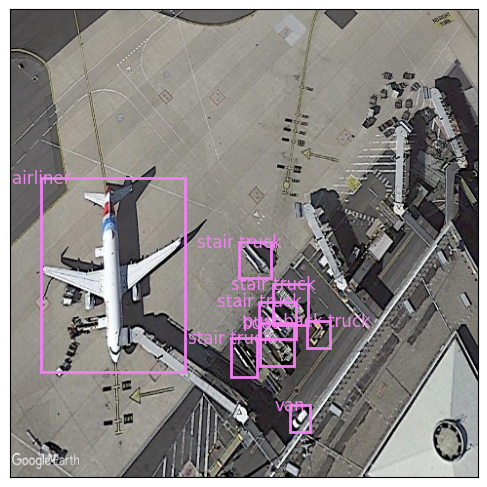

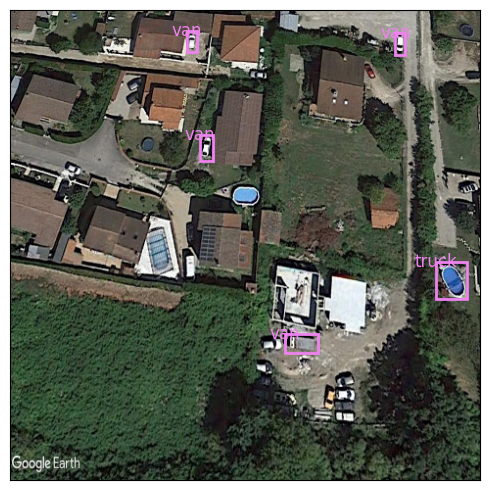

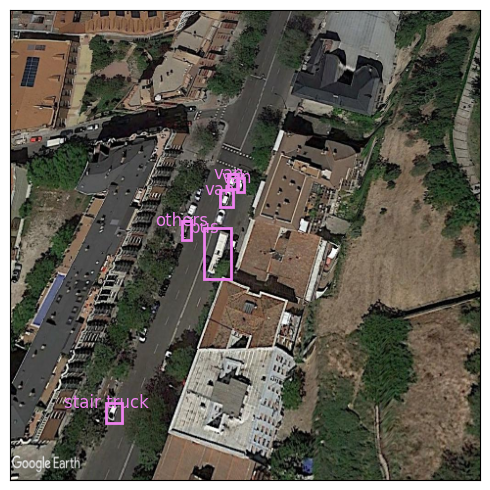

In [24]:
model_config = {
    "num_classes": 15,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}
model = FasterRCNN(model_config)
model.prepare()

model_path = "/home/dragik/data/FAIR_EO/SIMD/experiments/checkpoint.pth.tar"
labels = ["car","truck","van","long vehicle","bus","airliner","propeller aircraft","trainer aircraft","chartered aircraft","fighter aircraft","others","stair truck","pushback truck","helicopter","boat"]
transform = Resize()
model.load_model(model_path)

image = image_loader('/home/dragik/data/FAIR_EO/SIMD/validation/images/0015.jpg')
fig = model.detect_objects(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/SIMD/validation/images/0087.jpg')
fig = model.detect_objects(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/SIMD/validation/images/0265.jpg')
fig = model.detect_objects(image, labels, transform)